# A domain-expert agent solving Scheil solidification problems

## Notes:
> - Access to Thermo-Calc, TC-python and OpenAI API key are needed.
> - The customized database is collected from the examples in the TC-python package. 

#### Bo Ni, March 31, 2026

## 0. Check the floor

In [1]:
# # make into one block
# # 
# {
#     "tags": [
#         "hide-input",
#     ]
# }
# # 
#@CHech the base
import os, sys
print('Here is : \n', os.popen('pwd').read())
print('What we get in hardware: \n', os.popen('nvidia-smi').read())
kernel_name = os.path.basename(sys.executable.replace("/bin/python",""))
print ("The VirEnv kernal in action: ", kernel_name)
# 
# # make it work for both py and notebook
# try: 
#     from jupyter_client import kernelspec
#     spec = kernelspec.get_kernel_spec(kernel_name)
#     print("Path to it: ", spec.resource_dir)
# except:
#     print ("This suppose to be a .py run")
# # /path/to/my/kernel
try: 
    import torch
    print("What we have in software: \n Torch version:", torch.__version__) 
    print('Python: ', sys.version) # no switch case code
    # 
    print('What hardware the software see:')
    device = torch.device(
        "cuda:0" if torch.cuda.is_available() else "cpu"
    )
    print(device)
    num_of_gpus = torch.cuda.device_count()
    print("# of GPU", num_of_gpus)
    # 
    torch.cuda.empty_cache()
except:
    print ("No torch founded")
# 

Here is : 
 /trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_1/8_build_demos

What we get in hardware: 
 Wed Apr  1 12:52:09 2026       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 545.23.08              Driver Version: 545.23.08    CUDA Version: 12.3     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A40                     On  | 00000000:25:00.0 Off |                    0 |
|  0%   20C    P8              12W / 300W |      7MiB / 46068MiB |      0%      Default |
|                                     

In [2]:
# global setup
CKeys={}
CKeys['Debug']=1

CKeys['Debug']=0

In [3]:
# for TC-python 
# 
from dotenv import load_dotenv
load_dotenv('./local_safe/env_setup.custom')

True

In [4]:
# test
if CKeys['Debug']==1:
    print ( os.environ.get('LSHOST') )
    print ( os.environ.get('TC24A_HOME') )

172.24.116.37
/trace/group/tmousavi/software/Thermo-Calc/2024a


## Working part

In [5]:
import autogen
# 
import chromadb
# Accepted file formats for that can be stored in
# a vector database instance
from autogen.retrieve_utils import TEXT_FORMATS
# agents:
from autogen import AssistantAgent
from autogen.agentchat.contrib.retrieve_user_proxy_agent import RetrieveUserProxyAgent
# coding environment
from autogen.coding import LocalCommandLineCodeExecutor
from typing import Annotated

# others:
import json
from IPython.display import Image

import shutil

In [6]:
# config_list = autogen.config_list_from_json("OAI_CONFIG_LIST")

# ref:
# https://github.com/microsoft/autogen/blob/main/autogen/oai/openai_utils.py
config_list = autogen.config_list_from_json(
    env_or_file="Simple_OpenAI_Keys_Safe.json",
    file_location="../Local_Store/",
    filter_dict={
        "model": [
            "gpt-4o-2024-05-13",
            # "gpt-4o-2024-08-06",
            # "gpt-4o-mini",
        ],
    },
)

assert len(config_list) > 0
print("models to use: ", [config_list[i]["model"] for i in range(len(config_list))])

models to use:  ['gpt-4o-2024-05-13']


### Local setup

In [7]:
wk_dir = "../Local_Store/For_8_1_2/"


In [8]:
# clean everything

if CKeys['Debug']==1:
    ## clean everything
    if os.path.exists(wk_dir):
        shutil.rmtree(wk_dir)
        print (f"Remove everything...")

Remove everything...


In [9]:
# file store

if not os.path.exists(wk_dir):
    print (f"Create working path...")
    os.mkdir(wk_dir)

Create working path...


In [10]:
# subdir
code_dir = wk_dir + "coding/"
vedb_dir = wk_dir + "vector_db/"

### Construct agents

In [11]:
if CKeys['Debug']==1:
    print("Accepted file formats for `docs_path`:")
    print(TEXT_FORMATS)
    print (config_list[0]["model"])
    # print (config_list[1]["model"])

Accepted file formats for `docs_path`:
['txt', 'json', 'csv', 'tsv', 'md', 'html', 'htm', 'rtf', 'rst', 'jsonl', 'log', 'xml', 'yaml', 'yml', 'pdf', 'mdx']
gpt-4o-2024-05-13


#### 1. Assistant agent

In [12]:
# ++ ver 3
assi_agen_system_message="""
Role:
You are a senior expert in computational mateirals science, especially CALPHAD simulation.
You are equipped with function call namded, "retrieve_content", that you can call to retrieve useful information.
You write python script to solve CALPHAD simulation problems.
Note that suggesting function call is different from writing python script.

Rules:
1. You state your plan at the 1st response.
2. Based on the initial given task, you first decide whehter to call function "retrieve_content" to retrieve relevent examples/codes or not. If so, you provide a clear and precise demand of the question.
3. Next, based on the provided examples and information, you write python scripts to run Themro-Calc via tc_python to do calculations, like single equlibrium and Scheil calculaitons.
4. You also write python code for pre- or post-processing. For units, you use SI.
5. You write python script as a single formated block, like 
```python
code_block
```
6. You don't install new packages. All needed packages are already installed. 
7. You don't repeat the code block. In one response, you only write only one code block.
8. When the code run unsuccessuflly, you review the error information and debug the code.
9. When the debugging is challenging, you can call function "retrieve_content" to retrieve useful info for debuging.
10. When call function "retrieve_content", you summerize in the argument a clear and precise statement of the information you are looking for.
11. When facing challenges, you should work hard in solving them. Don't change the problem for a simpler one.
12. When the code run successfully, you review and sumarize the meaningful results. Do not repeat the code part for the summary. 
13. Only when in the previous response everything is done, you reply a solo word, 'TERMINATE', in a seperated response with nothing else.
"""
# 10. After you check and make sure everything is done, reply solely the word 'TERMINATE' in a seperate response.
assi_agen_description="Senior CALPHAD expert who can use TC-python to solve materials science problems."

In [13]:
assistant = AssistantAgent(
    name="Assistant",
    system_message=assi_agen_system_message,
    description=assi_agen_description,
    llm_config={
        "timeout": 1200,
        "cache_seed": 42,
        "config_list": config_list,
        "temperature": 0.3,
    },
)

#### 2. agent as an retrieval hand

In [14]:
# 2. the user proxy agent

# the hidden one that connect to the rag

proxy_rag_retrieve_config={
    "task": "code",
    "docs_path": [
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_01_Single_equilibrium_looping_and_3d_plotting.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_02_Single_equilibrium_solidus_and_liquidus_temperature.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_03_Scheil_mole_fraction_of_solid.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_04_Scheil_composition_distribution_Al_Si_Cu.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_05_Scheil_composition_profiles_Ni_base.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_06_Scheil_eutectic_fraction_Al_Si_Cu.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_07_Scheil_latent_heat_for_solidification_simulations.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_08_Property_diagram.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_09_Property_diagram_loop_parallel.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_10_Property_diagram_alloy_A_to_alloy_B.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_11_Phase_diagram.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_12_Phase_diagram_export_to_csv_file.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_13_Phase_diagram_single_phase_region_shift_Al_Si_Cu.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_14_Batch_equilibria.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_15_Scheil_back_diffusion.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_16_Scheil_Solute_Trapping_Al_Si_Cu.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_17_Material_to_Material_single_fraction_of_B.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_18_Material_to_Material_step_along_fraction_of_B.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_19_Material_to_Material_step_along_temperature.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/pyex_T_20_Material_to_Material_phase_diagram.md",
        "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_2/database_info_2024.md",
        
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_1/0_Example_Thermo_Calc.md",
        # "/trace/home/bni2/Thermo-Calc/2023b/SDK/TC-Python/Examples/Thermo-Calc/*py", # path to example.py files
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/Local_Store/For_0_6/TC_Python-2023.2.28684.30/tc_python/", # source code
        
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/0_code_tutorial_scheil_calculation.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/0_code_tutorial_single_equilibrium.md",
        # "/trace/group/tmousavi/bni2/1_JupyterGit/workspace/TC_Python_LLM_0/1_test_rag/code_repo/ver_0/1_supporting_info.md",
    ],
    "chunk_token_size": 1000,
    "model": config_list[0]["model"],
    # for vector-database
    "client": chromadb.PersistentClient(
        path=vedb_dir
    ),
    "overwrite": True,  # set to True if you want to overwrite an existing collection
    "get_or_create": False, # True, # False,  # set to False if don't want to reuse an existing collection
}
# 
proxy_rag_description="""
Assistant who has extra content retrieval power for solving difficult CALPHAD coding problems.
"""

In [15]:
# functions

def termination_msg(x):
    return isinstance(x, dict) and str(x.get("content", ""))[-9:].upper() == "TERMINATE"

In [16]:
proxy_rag = RetrieveUserProxyAgent(
    name="Proxy_w_RAG",
    is_termination_msg= termination_msg,
    human_input_mode="NEVER",
    default_auto_reply="Reply `TERMINATE` if the task is done.",
    max_consecutive_auto_reply=10, # 3,
    # 
    retrieve_config=proxy_rag_retrieve_config,
    # 
    code_execution_config=False,  # we don't want to execute code in this case.
    description="Assistant who has extra content retrieval power for solving difficult problems.",
)

#### 3. proxy agent with a coding hand

In [17]:
from types import SimpleNamespace

# Create a SimpleNamespace object with attributes
venv_SimNam = SimpleNamespace(
    env_dir="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling", 
    env_name="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling",
    bin_path="/trace/group/tmousavi/bni2/VirEnv/12_LLM_Modeling/bin/"
)

In [18]:
# the surface one that run the codes and functions

proxy_user_code_exe_config = {
    # the executor to run the generated code
    # ++
    # "executor": jupyter.JupyterCodeExecutor()
    # -- it's shell, no environment is activated
    "executor": LocalCommandLineCodeExecutor(
        # virtual_env_context="/trace/home/bni2/Group_WSpace_250GB/group_folder/bni2/VirEnv/6_LLM_Modelling",
        # ++
        virtual_env_context= venv_SimNam,
        work_dir= code_dir, # wk_dir + "coding"
    ),
}  # set to False if you don't want to execute the code

In [19]:

proxy_user = autogen.UserProxyAgent(
    name="User_Proxy",
    is_termination_msg=termination_msg,
    human_input_mode="NEVER",
    max_consecutive_auto_reply=10,
    # code running
    code_execution_config=proxy_user_code_exe_config,
)

#### 4. make connections

In [20]:
# now, we decrate the proxy_rag as helper through function calling

def retrieve_content(
    message: Annotated[
        str,
        "Refined message which keeps the original meaning and can be used to retrieve content for code generation and question answering.",
    ],
    n_results: Annotated[int, "number of results, choose 6"] = 6,
) -> str:
    
    proxy_rag.n_results = n_results  # Set the number of results to be retrieved.
    _context = {"problem": message, "n_results": n_results}
    ret_msg = proxy_rag.message_generator(
        proxy_rag, 
        None, 
        _context
    )
    return ret_msg or message

# Disable human input for retrieval hand since it only retrieves content.
proxy_rag.human_input_mode = "NEVER"  

In [21]:
# add the function to the players
# assistant: suggest where to call the function:          caller
# proxy_user: call the function and return the response:  executor

for caller in [assistant,]:
    # 
    d_retrieve_content = caller.register_for_llm(
        description="retrieve content for code generation and question answering.", 
        api_style="function"
    )(retrieve_content)

for executor in [proxy_user,]:
    executor.register_for_execution()(d_retrieve_content)

In [22]:
if CKeys['Debug']==1:
    # for debug purpose
    print (
        d_retrieve_content.tool_schema
    )

{'type': 'function', 'function': {'description': 'retrieve content for code generation and question answering.', 'name': 'retrieve_content', 'parameters': {'type': 'object', 'properties': {'message': {'type': 'string', 'description': 'Refined message which keeps the original meaning and can be used to retrieve content for code generation and question answering.'}, 'n_results': {'type': 'integer', 'default': 6, 'description': 'number of results, choose 6'}}, 'required': ['message']}}}


In [23]:
# reset all agents

def _reset_agents():
    assistant.reset()
    proxy_rag.reset()
    proxy_user.reset()

### Examples

#### Try some problems from the learning hub

In [24]:
# =======================================================================

code_problem_ver_3 = """
Task:
Perform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:
Fe - 1 wt-% C - 10 wt-% Cr

Please solve the task, print/plot the result 
and save them to json or png files.

"""

code_problem_ver_3 = """
Task:
Perform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:
Fe - 1 wt-% C - 10 wt-% Cr

Please solve the task, save the result in a json file and plot it in a png file. 
"""

In [25]:
_reset_agents()

In [26]:
chat_result_0 = proxy_user.initiate_chat(
    assistant, 
    message= code_problem_ver_3, 
    summary_method="reflection_with_llm",
    # search_string="spark"
)  # search_string is used as an extra filter for the embeddings search, in this case, we only want to search documents that contain "spark".


User_Proxy (to Assistant):


Task:
Perform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:
Fe - 1 wt-% C - 10 wt-% Cr

Please solve the task, save the result in a json file and plot it in a png file. 


--------------------------------------------------------------------------------
Assistant (to User_Proxy):

Plan:
1. Retrieve relevant examples and information for performing a Scheil calculation using Thermo-Calc via `tc_python`.
2. Write a Python script to perform the Scheil calculation for the given alloy composition (Fe - 1 wt-% C - 10 wt-% Cr).
3. Save the results in a JSON file.
4. Plot the latent heat of solidification and save the plot as a PNG file.

First, I will call the function `retrieve_content` to get relevant examples and information for performing a Scheil calculation using `tc_python`.

Let's proceed with the first step.
***** Suggested function call: retrieve_content *****
Arguments: 
{"message":"Examples and informati

2026-04-01 12:52:30,487 - autogen.agentchat.contrib.retrieve_user_proxy_agent - INFO - Found 24 chunks.
2026-04-01 12:52:30,514 - autogen.agentchat.contrib.vectordb.chromadb - INFO - No content embedding is provided. Will use the VectorDB's embedding function to generate the content embedding.


VectorDB returns doc_ids:  [['127e8d1b', '80f7d8d2', '07a8bfed', '6942b45c', 'cc2be9a4', '9629bbd7']]
Adding content of doc 127e8d1b to context.
Adding content of doc 80f7d8d2 to context.
Adding content of doc 07a8bfed to context.
Adding content of doc 6942b45c to context.
Adding content of doc cc2be9a4 to context.
Adding content of doc 9629bbd7 to context.

>>>>>>>> EXECUTED FUNCTION retrieve_content...
Call ID: None
Input arguments: {'message': 'Examples and information for performing a Scheil calculation using Thermo-Calc via tc_python, including saving results in a JSON file and plotting the latent heat of solidification.', 'n_results': 6}
Output:
You're a retrieve augmented coding assistant. You answer user's questions based on your own knowledge and the
context provided by the user.
If you can't answer the question with or without the current context, you should reply exactly `UPDATE CONTEXT`.
For code generation, you must obey the following rules:
Rule 1. You MUST NOT install an

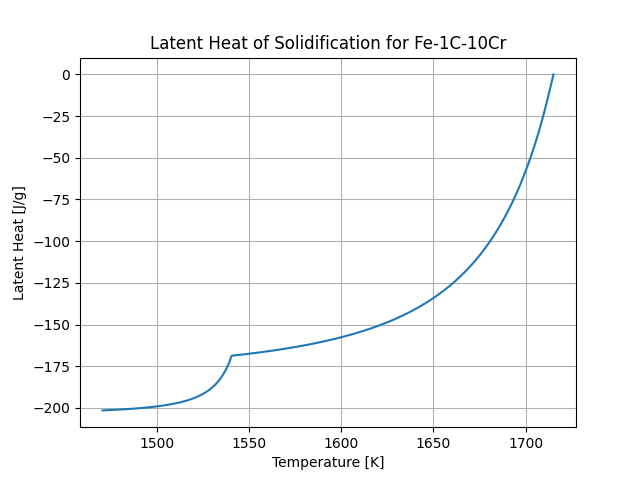

In [27]:
# check the result

Image(code_dir+'/latent_heat_solidification.png')

In [28]:
with open(code_dir+'/Fe_C_Cr_scheil_solidification.json') as f:
    d = json.load(f)
print (d)

{'temperature': [1470.66656, 1471.66656, 1472.66656, 1473.66656, 1474.66656, 1475.66656, 1476.66656, 1477.66656, 1478.66656, 1479.66656, 1480.66656, 1481.66656, 1482.66656, 1483.66656, 1484.66656, 1485.66656, 1486.66656, 1487.66656, 1488.66656, 1489.66656, 1490.66656, 1491.66656, 1492.66656, 1493.66656, 1494.66656, 1495.66656, 1496.66656, 1497.66656, 1498.66656, 1499.66656, 1500.66656, 1501.66656, 1502.66656, 1503.66656, 1504.66656, 1505.66656, 1506.66656, 1507.66656, 1508.66656, 1509.66656, 1510.66656, 1511.66656, 1512.66656, 1513.66656, 1514.66656, 1515.66656, 1516.66656, 1517.66656, 1518.66656, 1519.66656, 1520.66656, 1521.66656, 1522.66656, 1523.66656, 1524.66656, 1525.66656, 1526.66656, 1527.66656, 1528.66656, 1529.66656, 1530.66656, 1531.66656, 1532.66656, 1533.66656, 1534.66656, 1535.66656, 1536.66656, 1537.66656, 1538.66656, 1539.66656, 1540.66656, 1540.698435, 1541.04906, 1542.04906, 1543.04906, 1544.04906, 1545.04906, 1546.04906, 1547.04906, 1548.04906, 1549.04906, 1550.04906

In [29]:
print (
    f"Current Len of the chat history: {len(chat_result_0.chat_history)}"
)

Current Len of the chat history: 8


In [30]:
code_problem_ver_3_2 = """
Task:

Find the temperature where 80% is solidified as precisely as possible for the given composition:
Fe - 1 wt-% C - 10 wt-% Cr

Use the function scipy.interpolate.interp1d

Please solve the task, save the result in a json file and plot it in a png file. 
"""

In [31]:
proxy_user.send(
    recipient=assistant,
    message=code_problem_ver_3_2,
)

User_Proxy (to Assistant):


Task:

Find the temperature where 80% is solidified as precisely as possible for the given composition:
Fe - 1 wt-% C - 10 wt-% Cr

Use the function scipy.interpolate.interp1d

Please solve the task, save the result in a json file and plot it in a png file. 


--------------------------------------------------------------------------------
Assistant (to User_Proxy):

Plan:
1. Use the results from the previous Scheil calculation to find the temperature where 80% of the alloy is solidified.
2. Use `scipy.interpolate.interp1d` to interpolate the data and find the precise temperature.
3. Save the result in a JSON file.
4. Plot the solid fraction as a function of temperature and highlight the point where 80% is solidified, saving the plot as a PNG file.

Here is the complete Python script to achieve this:

```python
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from tc_python import *

# Define th

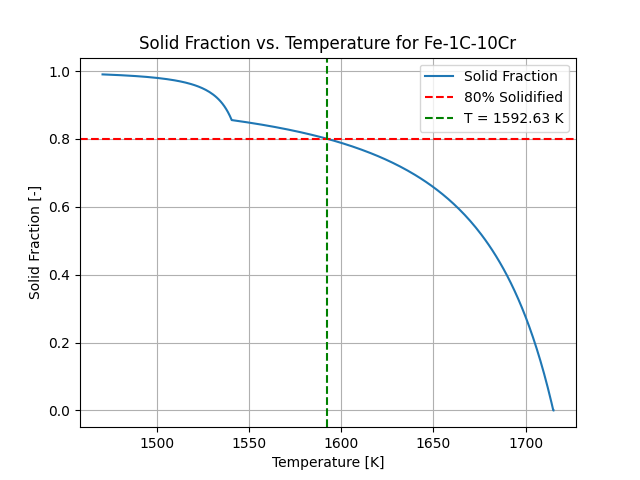

In [32]:
Image(code_dir + '/solid_fraction_vs_temperature.png')

In [33]:
with open(code_dir+'Fe_C_Cr_80_percent_solidified.json') as f:
    d = json.load(f)

print (d)

{'temperature_at_80_solid': 1592.6324996067196}


### Save the chat history

In [34]:
print (
    f"Current Len of the chat history: {len(chat_result_0.chat_history)}"
)

Current Len of the chat history: 14


In [35]:
# save the chat
import pickle

save_chat_hist = wk_dir + './chat_hist_from_0.pk'

if not os.path.exists(save_chat_hist):
    # writing in binary mode
    with open(save_chat_hist, 'wb') as out_handle:
        pickle.dump(chat_result_0, out_handle, pickle.HIGHEST_PROTOCOL)

In [36]:
chat_result_0

ChatResult(chat_id=None, chat_history=[{'content': '\nTask:\nPerform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:\nFe - 1 wt-% C - 10 wt-% Cr\n\nPlease solve the task, save the result in a json file and plot it in a png file. \n', 'role': 'assistant', 'name': 'User_Proxy'}, {'content': "Plan:\n1. Retrieve relevant examples and information for performing a Scheil calculation using Thermo-Calc via `tc_python`.\n2. Write a Python script to perform the Scheil calculation for the given alloy composition (Fe - 1 wt-% C - 10 wt-% Cr).\n3. Save the results in a JSON file.\n4. Plot the latent heat of solidification and save the plot as a PNG file.\n\nFirst, I will call the function `retrieve_content` to get relevant examples and information for performing a Scheil calculation using `tc_python`.\n\nLet's proceed with the first step.", 'function_call': {'arguments': '{"message":"Examples and information for performing a Scheil calculation using 

## End of working code